### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-07-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2015-07-01")
pred_end_date = pd.to_datetime("2022-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preperation for Prediction

In [11]:
DMFEM = data.copy()
DMFEM = DMFEM[DMFEM['category']=='meat, fish and eggs']
DMFEM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
72,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (beef),beef,NaN,KG,actual,Retail,MMK,2424.24,1.3619
73,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,2909.09,1.6343
74,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429


In [12]:
DMFEM = DMFEM[['date', 'price']]
DMFEM['date'] = pd.to_datetime(DMFEM['date'])
mask = (DMFEM['date']>=obv_st_date) & (DMFEM['date']<=obv_end_date)
DMFEM = DMFEM.loc[mask]
DMFEM = DMFEM.set_index('date')
DMFEM.head()

,price
date,
2008-07-15,2424.24
2008-07-15,4848.48
2008-07-15,3636.36
2008-07-15,3636.36
2008-07-15,3636.36


In [13]:
DMFEM = DMFEM.resample('MS').mean()
DMFEM.head()

,price
date,
2008-07-01,3636.360000
2008-08-01,3303.028333
2008-09-01,3505.048333
2008-10-01,3404.038333
2008-11-01,3383.835000


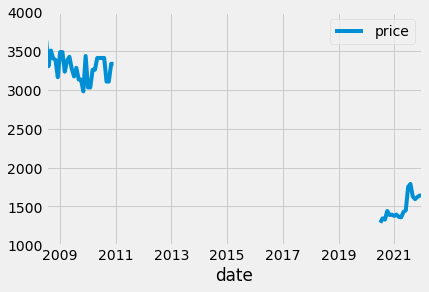

In [14]:
DMFEM.plot(grid=True)
plt.show()

There is too many missing data. We need to cut out date.

### According to this dataframe, we need to reset again datatime.

In [15]:
obv_st_date = pd.to_datetime("2020-09-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2020-09-01")
pred_end_date = pd.to_datetime("2022-09-01")

In [16]:
mask = (DMFEM.index>=obv_st_date) & (DMFEM.index<=obv_end_date)
DMFEM = DMFEM.loc[mask]
DMFEM.shape

(17, 1)

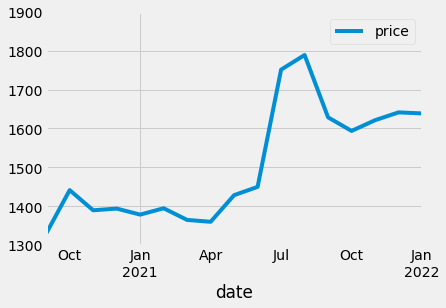

In [17]:
DMFEM = DMFEM.dropna()
DMFEM.plot(grid=True)
plt.show()

There is log like trend

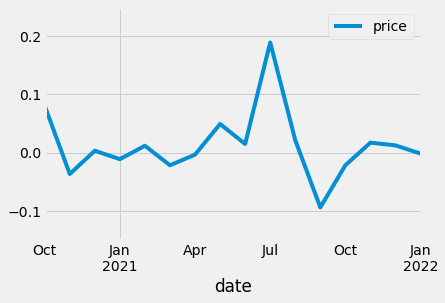

In [18]:
DMFEM_diff_log = np.log(DMFEM).diff().dropna()
DMFEM_diff_log.plot(grid=True)
plt.show()

##### Checking Random Walk

In [19]:
RW_DMFEM = adfuller(DMFEM_diff_log)
RW_DMFEM[1] # print P-value. If p-value<5%, reject null hypothesis

0.0051740569734172424

##### Plotting ACF and PACF

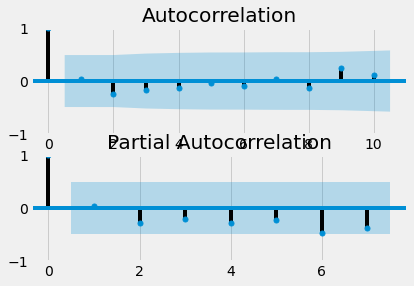

In [20]:
fig, axes=plt.subplots(2,1)
plot_acf(DMFEM_diff_log, lags=10, ax=axes[0])
plot_pacf(DMFEM_diff_log, lags=7, ax=axes[1])
plt.show()

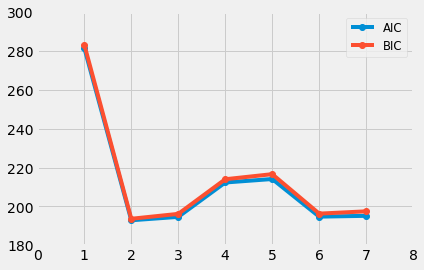

In [21]:
AIC, BIC = AIC_BIC_withOrderRange(DMFEM,p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [22]:
AIC, BIC

(array([299.17409475, 281.50902493, 192.87460785, 194.62049323,
        212.31314683, 214.0934423 , 194.74469084, 195.15888722]),
 array([300.0073081 , 283.17545162, 193.64719658, 196.16567067,
        213.97957352, 216.59308234, 196.28986828, 197.47665338]))

We will run again 2:(0,1,0), 3:(0,1,1), 6:(1,1,0), 7:(1,1,1)

In [23]:
mod_orders = [
    (0,1,0), 
    (0,1,1), 
    (1,1,0), 
    (1,1,1)
]

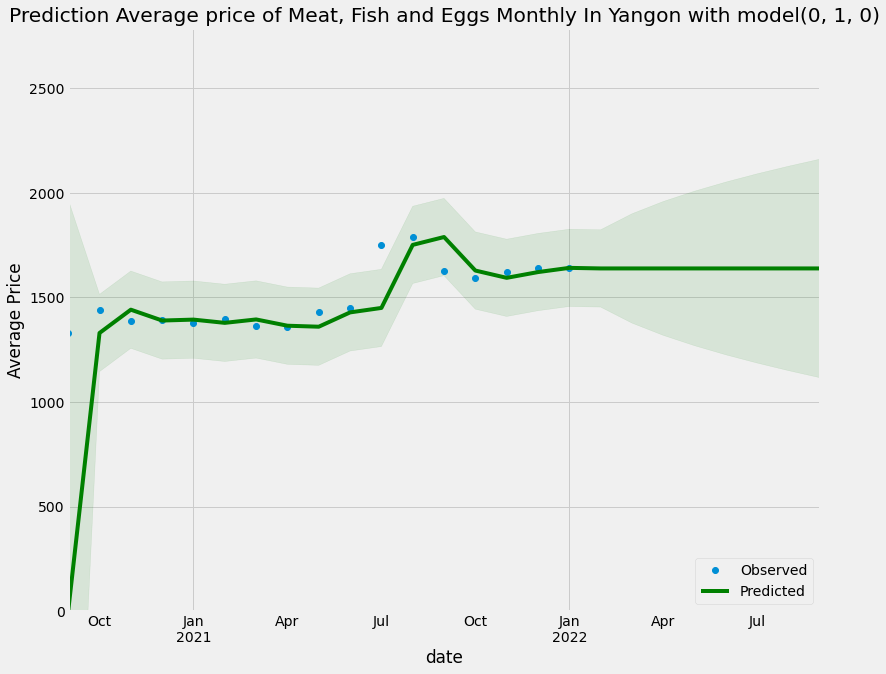

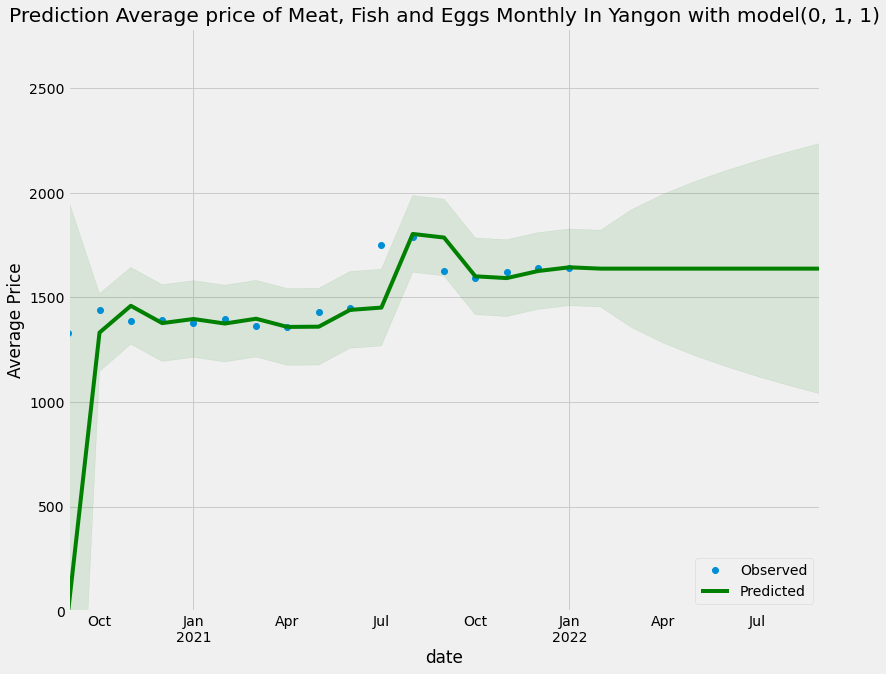

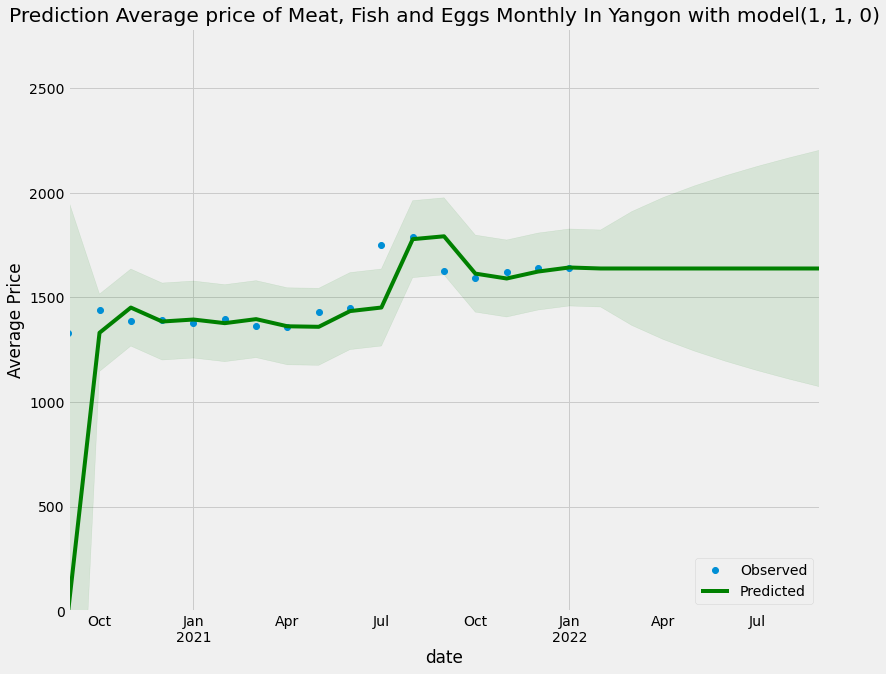

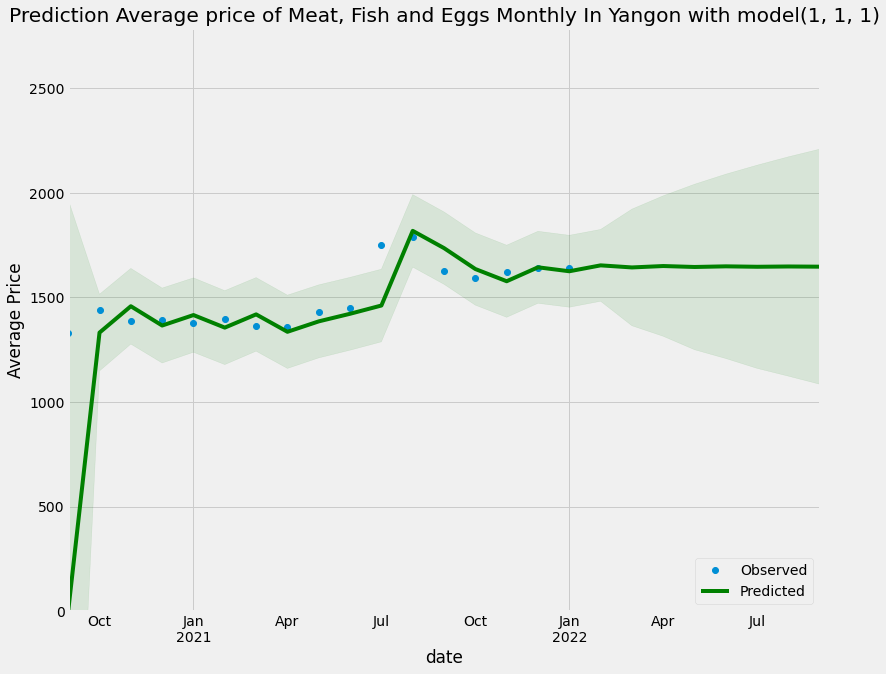

In [24]:
DMFEM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DMFEM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Meat, Fish and Eggs Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFEM_models.append(model)

Now we choose (0,1,0)

In [25]:
DMFEM_model = DMFEM_models[0]

In [26]:
DMFEM_pred = DMFEM_model.predict(pred_st_date, pred_end_date)
DMFEM_pred

2020-09-01       0.000000
2020-10-01    1329.946984
2020-11-01    1441.404091
2020-12-01    1389.506351
2021-01-01    1393.934426
2021-02-01    1378.411765
2021-03-01    1394.732394
2021-04-01    1364.745909
2021-05-01    1359.974348
2021-06-01    1428.460933
2021-07-01    1449.800000
2021-08-01    1751.243590
2021-09-01    1788.935065
2021-10-01    1628.534337
2021-11-01    1593.701149
2021-12-01    1621.202619
2022-01-01    1641.388539
2022-02-01    1638.666667
2022-03-01    1638.666667
2022-04-01    1638.666667
2022-05-01    1638.666667
2022-06-01    1638.666667
2022-07-01    1638.666667
2022-08-01    1638.666667
2022-09-01    1638.666667
Freq: MS, Name: predicted_mean, dtype: float64